[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_supply_schedule/BA_L1_supply_schedule.ipynb)

# BA_L1_supply_schedule: The Supply Schedule

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The Bitcoin supply path implied by the protocol rule (block subsidy of 50 BTC halved every 210 000 blocks) on a simulated calendar with exactly 144 blocks a day, 2009 to 2040, and its annual growth rate on a log scale.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Method

The block subsidy at block height $h$ is $s(h) = 50 \cdot 2^{-\lfloor h/210\,000 \rfloor}$ BTC, halved every
210 000 blocks (about four years). Total supply is a geometric series,

$$S_\infty = 210\,000 \sum_{k=0}^{\infty} 50 \cdot 2^{-k} = 21 \text{ million BTC}.$$

The simulated calendar assumes exactly 144 blocks a day (one every 600 seconds) from 3 January 2009; the supply on
day $t$ is the cumulated subsidy, and the annual supply growth is $100\,(S_t - S_{t-365})/S_{t-365}$, the growth of
the money stock (not consumer-price inflation).

**How to read the chart.** Left: the supply path and the 21 million cap. Right: the annual supply growth on a log
scale; it halves at every halving. Dotted green lines: the four halvings on the simulated calendar (height
$210\,000\,k$ after $210\,000\,k/144$ days). The actual halvings came earlier (28 November 2012, 9 July 2016,
11 May 2020, 20 April 2024) because blocks arrived faster than every 10 minutes.

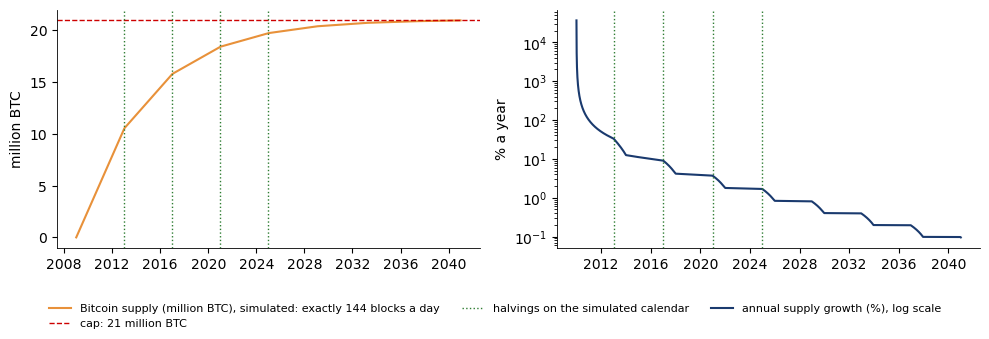

In [5]:
# supply path of the protocol rule with exactly 144 blocks a day: subsidy 50 BTC halved every 210 000 blocks
days = pd.date_range('2009-01-03', '2040-12-31', freq='D')
height = np.arange(len(days)) * 144
subsidy = 50 * 0.5 ** np.floor(height / 210_000)
S_rule = pd.Series(np.minimum(np.cumsum(subsidy * 144), 21e6), index=days)

infl = 100 * S_rule.diff(365) / S_rule.shift(365)
halvings_sim = [days[0] + pd.Timedelta(days=210_000 * k / 144) for k in range(1, 5)]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(S_rule.index, S_rule / 1e6, color=BTC, label='Bitcoin supply (million BTC), simulated: exactly 144 blocks a day')
ax[0].axhline(21, color=RED, ls='--', lw=1, label='cap: 21 million BTC')
ax[0].set_ylabel('million BTC')
ax[1].plot(infl.index, infl, color=BLUE, label='annual supply growth (%), log scale')
ax[1].set_yscale('log'); ax[1].set_ylabel('% a year')
for i, d in enumerate(halvings_sim):
    for a in ax:
        a.axvline(d, color=GREEN, ls=':', lw=1, label='halvings on the simulated calendar' if (i == 0 and a is ax[0]) else None)
slide_legend(fig, 0.14)
save_fig(fig, 'ba_l1_supply_schedule')

In [6]:
dates = ['2013-01-01', '2017-01-01', '2021-01-01', '2025-01-01', '2026-09-18', '2032-01-01']
tab = pd.DataFrame({'supply by the rule (million BTC)': [S_rule[d] / 1e6 for d in dates],
                    'annual supply growth (%)': [infl[d] for d in dates]},
                   index=['1 Jan 2013', '1 Jan 2017', '1 Jan 2021', '1 Jan 2025', '18 Sep 2026', '1 Jan 2032'])
print(tab.round(3).to_string())
print(f'\nYear in which supply reaches 99% of the cap: {S_rule[S_rule >= 0.99 * 21e6].index[0].year}')
print('Halvings on the simulated calendar:', ', '.join(f'{d:%d %b %Y}' for d in halvings_sim))

             supply by the rule (million BTC)  annual supply growth (%)
1 Jan 2013                             10.508                    33.288
1 Jan 2017                             15.761                     9.041
1 Jan 2021                             18.384                     3.669
1 Jan 2025                             19.695                     1.675
18 Sep 2026                            19.976                     0.829
1 Jan 2032                             20.596                     0.400

Year in which supply reaches 99% of the cap: 2035
Halvings on the simulated calendar: 31 Dec 2012, 28 Dec 2016, 26 Dec 2020, 23 Dec 2024
